In [ ]:
from tensorflow.keras.datasets import cifar10

In [ ]:
# Load CIFAR-10
(X_train, y_train), (X_test, y_test) = cifar10.load_data()

# Normalize images to [0,1]
X_train = X_train.astype("float32") / 255.0
X_test  = X_test.astype("float32") / 255.0

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 19s 0us/step


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

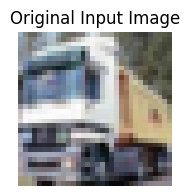

In [ ]:
# Pick one test image
img = X_train[1]
plt.figure(figsize=(2,2))
plt.imshow(img)
plt.title("Original Input Image")
plt.axis("off")
plt.show()

In [ ]:
from tensorflow.keras.utils import to_categorical

# One-hot encode labels
y_train_cat = to_categorical(y_train, 10)
y_test_cat  = to_categorical(y_test, 10)

class_names = [
    "airplane","automobile","bird","cat","deer",
    "dog","frog","horse","ship","truck"
]

print("Training data shape:", X_train.shape)
print("Test data shape:", X_test.shape)


Training data shape: (50000, 32, 32, 3)
Test data shape: (10000, 32, 32, 3)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Dense, Dropout, Flatten,
    Conv2D, MaxPooling2D
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

In [ ]:
cnn = Sequential([
    Conv2D(32, (3,3), activation='relu', padding='same', input_shape=(32,32,3)),
    MaxPooling2D((2,2)),

    Conv2D(64, (5,5), activation='relu', padding='same'),
    MaxPooling2D((2,2)),

    Conv2D(128, (7,7), activation='relu', padding='same'),
    MaxPooling2D((2,2)),

    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.8),
    Dense(10, activation='softmax')
])

cnn.compile(
    optimizer=Adam(),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

cnn.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 980,810 (3.74 MB)

 Trainable params: 980,810 (3.74 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stopping = EarlyStopping(
    monitor='val_loss',  # Monitor validation loss
    patience=5,          # Number of epochs with no improvement after which training will be stopped
    restore_best_weights=True  # Restore model weights from the epoch with the best value of the monitored quantity
)

import time
start = time.time()
history_cnn = cnn.fit(
    X_train, y_train_cat,
    validation_split=0.1,
    epochs=25,
    batch_size=256,
    callbacks=[early_stopping],
    verbose=1
)
cnn_time = time.time() - start

Epoch 1/25
176/176 ━━━━━━━━━━━━━━━━━━━━ 14s 48ms/step - accuracy: 0.2092 - loss: 2.0958 - val_accuracy: 0.4666 - val_loss: 1.4850
Epoch 2/25
176/176 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.4163 - loss: 1.5963 - val_accuracy: 0.5448 - val_loss: 1.2717
Epoch 3/25
176/176 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.4995 - loss: 1.4024 - val_accuracy: 0.5872 - val_loss: 1.1734
Epoch 4/25
176/176 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.5651 - loss: 1.2479 - val_accuracy: 0.6384 - val_loss: 1.0220
Epoch 5/25
176/176 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.6155 - loss: 1.0997 - val_accuracy: 0.6686 - val_loss: 0.9326
Epoch 6/25
176/176 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.6536 - loss: 1.0044 - val_accuracy: 0.7086 - val_loss: 0.8565
Epoch 7/25
176/176 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.6799 - loss: 0.9245 - val_accuracy: 0.7240 - val_loss: 0.7998
Epoch 8/25
176/176 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.7178 - loss: 0.8233 - val_acc

In [ ]:
print(cnn_time)

72.37755084037781


In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

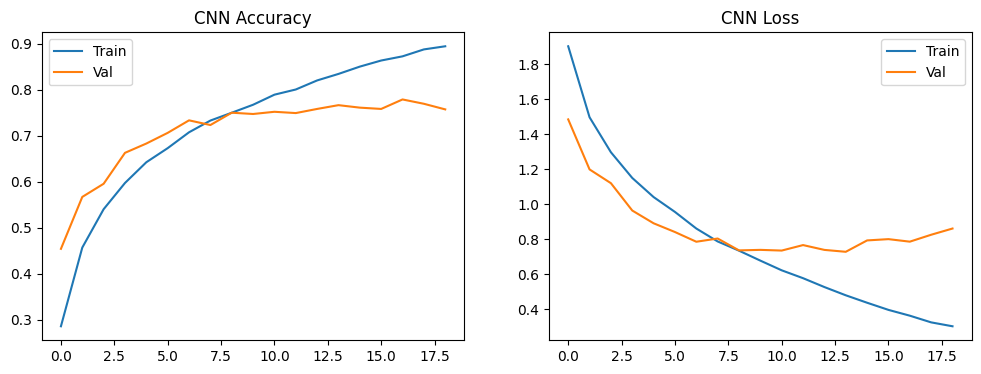

In [ ]:
def plot_history(history, title):
    plt.figure(figsize=(12,4))

    plt.subplot(1,2,1)
    plt.plot(history.history['accuracy'], label='Train')
    plt.plot(history.history['val_accuracy'], label='Val')
    plt.title(f'{title} Accuracy')
    plt.legend()

    plt.subplot(1,2,2)
    plt.plot(history.history['loss'], label='Train')
    plt.plot(history.history['val_loss'], label='Val')
    plt.title(f'{title} Loss')
    plt.legend()

    plt.show()

plot_history(history_cnn, "CNN")


In [ ]:
cnn_test_loss, cnn_test_acc = cnn.evaluate(X_test, y_test_cat, verbose=0)

print("CNN Test Accuracy:", cnn_test_acc)

CNN Test Accuracy: 0.7526000142097473


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step

CNN Classification Report
              precision    recall  f1-score   support

    airplane       0.75      0.79      0.77      1000
  automobile       0.89      0.85      0.87      1000
        bird       0.65      0.69      0.67      1000
         cat       0.57      0.56      0.57      1000
        deer       0.69      0.72      0.70      1000
         dog       0.71      0.61      0.66      1000
        frog       0.84      0.79      0.81      1000
       horse       0.82      0.79      0.80      1000
        ship       0.80      0.88      0.84      1000
       truck       0.81      0.84      0.82      1000

    accuracy                           0.75     10000
   macro avg       0.75      0.75      0.75     10000
weighted avg       0.75      0.75      0.75     10000



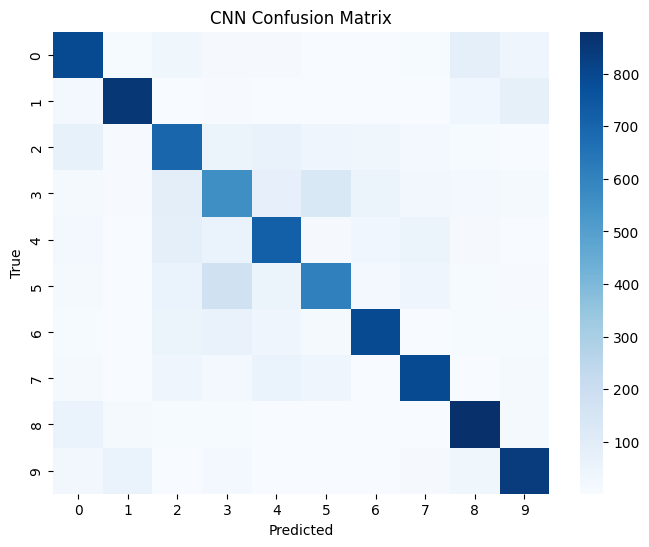

In [ ]:
def evaluate_model(model, X_test, y_test, name):
    y_pred = np.argmax(model.predict(X_test), axis=1)
    y_true = y_test.flatten()

    cm = confusion_matrix(y_true, y_pred)

    print(f"\n{name} Classification Report")
    print(classification_report(y_true, y_pred, target_names=class_names))

    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=False, cmap="Blues")
    plt.title(f"{name} Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

    return y_pred

cnn_preds = evaluate_model(cnn, X_test, y_test, "CNN")

In [ ]:
from tensorflow.keras.models import Model

layer_outputs = []
layer_names = []

for layer in cnn.layers:
    if isinstance(layer, (Conv2D, MaxPooling2D)):
        layer_outputs.append(layer.output)
        layer_names.append(layer.name)

feature_extractor = Model(inputs=cnn.layers[0].input, outputs=layer_outputs)

In [ ]:
# Add batch dimension
img_batch = np.expand_dims(img, axis=0)

feature_maps = feature_extractor.predict(img_batch)


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 645ms/step


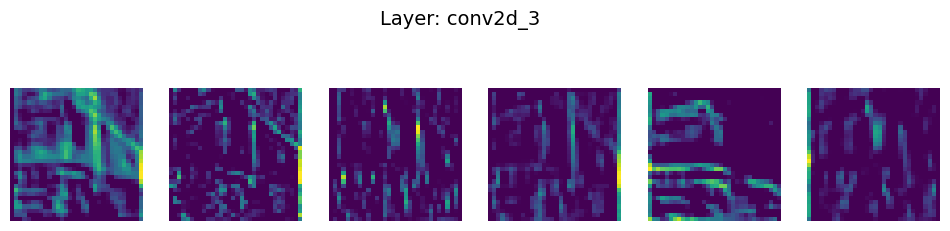

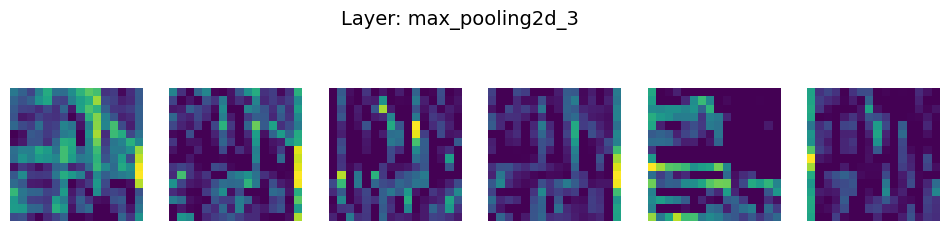

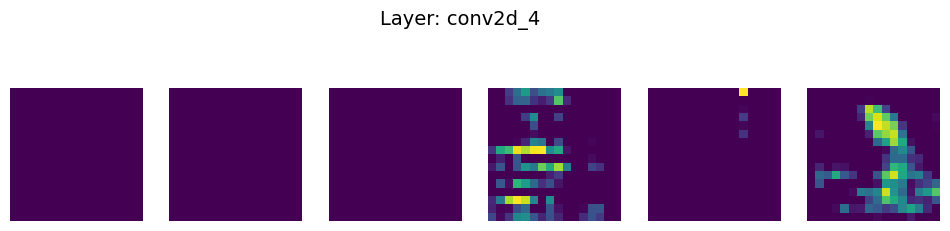

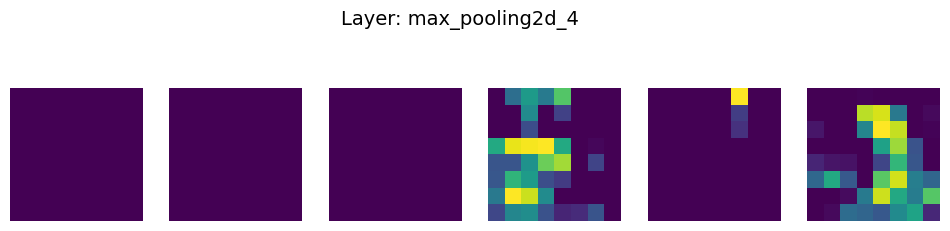

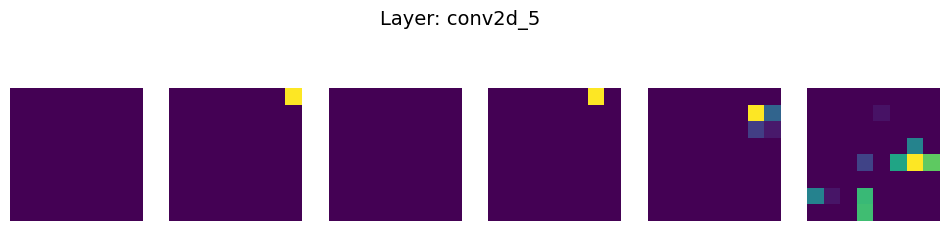

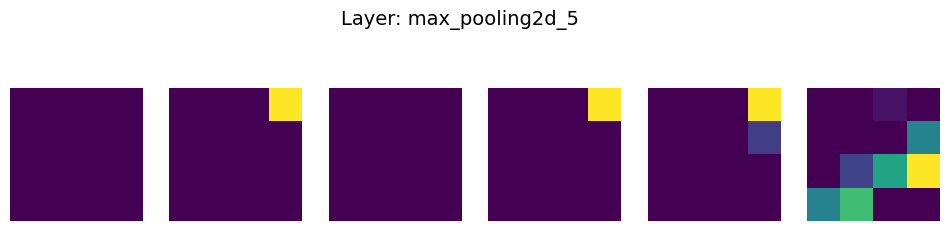

In [ ]:
def visualize_feature_maps(feature_maps, layer_names):
    for fmap, name in zip(feature_maps, layer_names):
        num_channels = fmap.shape[-1]
        plt.figure(figsize=(12,3))
        plt.suptitle(f"Layer: {name}", fontsize=14)

        for i in range(min(6, num_channels)):
            plt.subplot(1,6,i+1)
            plt.imshow(fmap[0, :, :, i], cmap='viridis')
            plt.axis('off')

        plt.show()

visualize_feature_maps(feature_maps, layer_names)

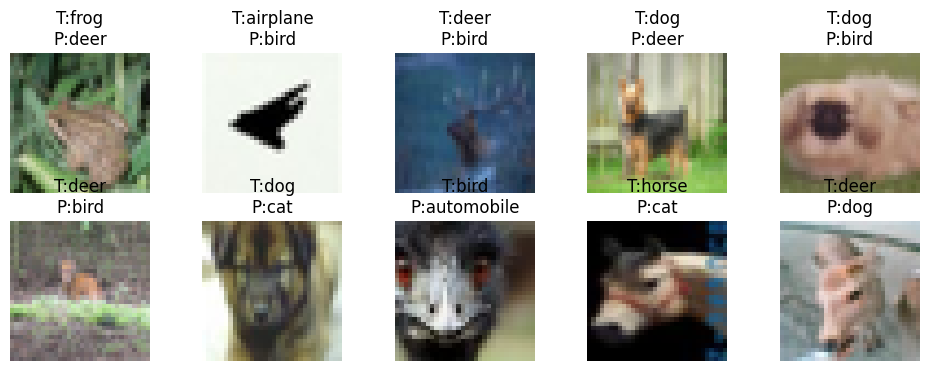

In [ ]:
def show_misclassified(X, y_true, y_pred, class_names, n=10):
    mis_idx = np.where(y_true.flatten() != y_pred)[0][:n]

    plt.figure(figsize=(12,4))
    for i, idx in enumerate(mis_idx):
        plt.subplot(2,5,i+1)
        plt.imshow(X[idx])
        plt.title(f"T:{class_names[y_true[idx][0]]}\nP:{class_names[y_pred[idx]]}")
        plt.axis('off')
    plt.show()

show_misclassified(X_test, y_test, cnn_preds, class_names)

In [ ]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["CNN"],
    "Parameters": [cnn.count_params()],
    "Test Accuracy": [cnn_test_acc],
    "Training Time (sec)": [cnn_time]
})

comparison

,Model,Parameters,Test Accuracy,Training Time (sec)
0,CNN,980810,0.7526,72.377551
